# Tarea 2 — Análisis y predicción del peso al nacer
**Jesid Alexander López Álvarez · Introducción a la programación científica · 2026-2**

**Pregunta:** ¿cuánto mejora un árbol de decisión la estimación del peso en gramos frente a predecir siempre la media, dentro de los registros de bajo peso al nacer de Medellín?

El análisis parte del CSV crudo de SIVIGILA y sigue el proceso de lectura → parseo → auditoría → decisiones → gráficas → baseline → árbol → conclusiones.

**Alcance:** ejercicio retrospectivo y académico condicionado a los casos notificados. No estima la probabilidad de bajo peso en todos los nacimientos ni sirve como herramienta clínica. `y = peso_nacer` procede de la columna original y no se imputa.

## 1. Fuente, ejecución y reproducibilidad
- Fuente: SIVIGILA / Alcaldía de Medellín, MEData, registros de 2011–2021. [Portal MEData](https://medata.app.medellin.gov.co/), [ficha histórica del conjunto](https://medata.gov.co/dataset/1-026-22-000129).
- Archivo: `data/sivigila_bpn.csv`. Se descarga una **revisión fija** desde GitHub y se verifica su SHA-256.
- Ejecutar **Entorno de ejecución → Ejecutar todas** en Colab. Se requiere internet para la primera lectura; no se necesitan rutas del computador, montar Drive ni subir archivos en cada sesión.
- Se usan pandas, NumPy, matplotlib y scikit-learn disponibles en Colab. Se imprimen sus versiones. La semilla es 42. Las salidas se guardan en `salidas_tarea2/` dentro de la sesión.
- La ficha histórica no ofrece aquí un diccionario verificable del extracto ni una licencia específica archivada. Se documenta esa limitación y no se redistribuye otra copia del dato crudo.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, r2_score

SEMILLA = 42
SALIDAS = Path("salidas_tarea2")
SALIDAS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
print({"Python": platform.python_version(), "pandas": pd.__version__,
       "NumPy": np.__version__, "matplotlib": matplotlib.__version__,
       "scikit-learn": sklearn.__version__, "semilla": SEMILLA})

{'Python': '3.14.2', 'pandas': '3.0.5', 'NumPy': '2.5.2', 'matplotlib': '3.11.1', 'scikit-learn': '1.9.1', 'semilla': 42}


### 1.1 Lectura como texto, antes de interpretar
Se fija separador coma y codificación UTF-8. `keep_default_na=False` y `na_filter=False` conservan literalmente vacíos, `SD`, `SIN INFORMACION` y las comillas del archivo: así se puede contar por separado lo ausente en origen, los centinelas y los errores de conversión. El decimal con coma se normaliza **en el parseo**, no alterando a ciegas todo el CSV.

In [2]:
URL_DATOS = ("https://raw.githubusercontent.com/thecont15/"
             "Introduccion-a-la-programacion-cientifica/"
             "70111e696a54f91fe73727847d9952f8f92afbca/data/sivigila_bpn.csv")
SHA256_ESPERADO = "1a55372c433adb33d01ebfb6d769476c0350bde4509ccae683f31e3d9f1eb5d2"
with urlopen(URL_DATOS, timeout=60) as respuesta:
    contenido = respuesta.read()
sha256 = hashlib.sha256(contenido).hexdigest()
if sha256 != SHA256_ESPERADO:
    raise ValueError("La descarga no corresponde al CSV documentado; revisar la fuente.")

datos_crudos = pd.read_csv(BytesIO(contenido), sep=",", encoding="utf-8",
                          decimal=".", dtype=str, keep_default_na=False, na_filter=False)
COLUMNAS_ESPERADAS = [
    "id", "semana", "edad_", "uni_med_", "sexo_", "nombre_barrio", "comuna",
    "tipo_ss_", "cod_ase_", "fec_con_", "ini_sin_", "tip_cas_", "pac_hos_",
    "peso_nacer", "talla_nacer", "sem_gest", "niv_edu_ma", "evento", "year_"
]
if list(datos_crudos.columns) != COLUMNAS_ESPERADAS:
    raise ValueError("Cambió el esquema del extracto; no continuar con reglas antiguas.")
print(f"Después de leer: {datos_crudos.shape[0]:,} filas × {datos_crudos.shape[1]} columnas")
print("SHA-256:", sha256)
display(datos_crudos.head())
datos_crudos.info()

Después de leer: 10,187 filas × 19 columnas
SHA-256: 1a55372c433adb33d01ebfb6d769476c0350bde4509ccae683f31e3d9f1eb5d2


,id,semana,edad_,uni_med_,sexo_,nombre_barrio,comuna,tipo_ss_,cod_ase_,fec_con_,ini_sin_,tip_cas_,pac_hos_,peso_nacer,talla_nacer,sem_gest,niv_edu_ma,evento,year_
0,1,41,28,1,M,Oriente,Manrique,N,"\""\""",01/01/1900,01/01/1900,4,1,2440,49,38,SD,BAJO PESO AL NACER,2011
1,2,41,17,1,F,SIN INFORMACION,SIN INFORMACION,S,EPS003,01/01/1900,01/01/1900,4,1,2490,46,37,SD,BAJO PESO AL NACER,2011
2,3,44,19,1,F,Villa del Socorro,Santa Cruz,S,EPS003,01/01/1900,01/01/1900,4,1,2290,47,37,SD,BAJO PESO AL NACER,2011
3,4,47,27,1,F,Las Independencias,San Javier,S,EPS003,01/01/1900,01/01/1900,4,1,2400,49,37,SD,BAJO PESO AL NACER,2011
4,5,47,23,1,F,Granizal,Popular,N,"\""\""",01/01/1900,01/01/1900,4,1,2240,47,38,SD,BAJO PESO AL NACER,2011


<class 'pandas.DataFrame'>
RangeIndex: 10187 entries, 0 to 10186
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   id             10187 non-null  str  
 1   semana         10187 non-null  str  
 2   edad_          10187 non-null  str  
 3   uni_med_       10187 non-null  str  
 4   sexo_          10187 non-null  str  
 5   nombre_barrio  10187 non-null  str  
 6   comuna         10187 non-null  str  
 7   tipo_ss_       10187 non-null  str  
 8   cod_ase_       10187 non-null  str  
 9   fec_con_       10187 non-null  str  
 10  ini_sin_       10187 non-null  str  
 11  tip_cas_       10187 non-null  str  
 12  pac_hos_       10187 non-null  str  
 13  peso_nacer     10187 non-null  str  
 14  talla_nacer    10187 non-null  str  
 15  sem_gest       10187 non-null  str  
 16  niv_edu_ma     10187 non-null  str  
 17  evento         10187 non-null  str  
 18  year_          10187 non-null  str  
dtypes: str(19)
memo

## 2. Parseo: distinguir un centinela de un error
Cada columna conserva una pista de auditoría. Un vacío ya existía; `SD` o `01/01/1900` es un centinela reconocido; un texto que queda en `NaN` después de intentar convertirlo es un **fallo de parseo**. La tabla muestra los tres conteos sin mezclarlos.

Se recortan espacios y se homogeneizan mayúsculas en categorías. No se traducen códigos educativos a etiquetas no verificadas: el [diccionario INS 2018–2020](https://www.ins.gov.co/Direcciones/Vigilancia/Lineamientosydocumentos/3.%20Diccionario_de_datos_Sivigila%202018_2020.pdf) enumera cuatro códigos para `NIV_EDU_MA`, pero este extracto tiene también `5`. Se conservan los códigos originales hasta confirmar su equivalencia para todos los años.

In [3]:
numericas = ["id", "semana", "edad_", "uni_med_", "peso_nacer",
             "talla_nacer", "sem_gest", "year_"]
fechas = ["fec_con_", "ini_sin_"]
categoricas = [c for c in COLUMNAS_ESPERADAS if c not in numericas + fechas]
centinelas_generales = {"SD", "SIN INFORMACION", "SIN INFORMACIÓN", '""', "NULL", "N/A"}
df = datos_crudos.copy()
registro_parseo = []

for columna in COLUMNAS_ESPERADAS:
    original = datos_crudos[columna].astype("string").str.strip()
    vacios = original.eq("")
    centinelas = original.str.upper().isin(centinelas_generales)
    if columna in fechas:
        centinelas = centinelas | original.eq("01/01/1900")
    candidata = original.mask(vacios | centinelas)
    if columna in numericas:
        convertida = pd.to_numeric(candidata.str.replace(",", ".", regex=False),
                                   errors="coerce").astype(float)
    elif columna in fechas:
        convertida = pd.to_datetime(candidata, format="%d/%m/%Y", errors="coerce")
    else:
        convertida = candidata.str.upper()
    fallos = candidata.notna() & convertida.isna()
    df[columna] = convertida
    registro_parseo.append({
        "variable": columna, "vacios_origen": int(vacios.sum()),
        "centinelas_reconocidos": int(centinelas.sum()),
        "fallos_conversion": int(fallos.sum()),
        "faltantes_despues": int(convertida.isna().sum()),
        "ejemplos_fallo": ", ".join(original[fallos].unique()[:4])
    })

auditoria_parseo = pd.DataFrame(registro_parseo).set_index("variable")
display(auditoria_parseo)
print("Total de fallos de conversión:", auditoria_parseo.fallos_conversion.sum())
auditoria_parseo.to_csv(SALIDAS / "auditoria_parseo.csv", encoding="utf-8", index=True)

,vacios_origen,centinelas_reconocidos,fallos_conversion,faltantes_despues,ejemplos_fallo
variable,,,,,
id,0,0,0,0,
semana,0,0,0,0,
edad_,0,0,0,0,
uni_med_,0,0,0,0,
sexo_,0,0,0,0,
nombre_barrio,0,420,0,420,
comuna,0,420,0,420,
tipo_ss_,0,0,0,0,
cod_ase_,0,0,0,0,


Total de fallos de conversión: 0


## 3. Auditoría y decisiones por variable
La auditoría revisa tipos, faltantes, categorías, duplicados y rangos. Se detectan atípicos mediante IQR **sin borrarlos**. Los umbrales de revisión no se presentan como diagnósticos médicos.

La edad y el sexo genéricos de la notificación no se interpretan automáticamente como los del bebé o de la madre. La distribución de `sexo_` se muestra para evidenciar esta ambigüedad. El modelo usa un conjunto conservador de predictores y deja fuera esos campos hasta confirmar el diccionario específico.

In [4]:
def auditar(tabla):
    return pd.DataFrame({
        "tipo": tabla.dtypes.astype(str),
        "faltantes": tabla.isna().sum(),
        "faltantes_pct": tabla.isna().mean().mul(100).round(2),
        "distintos": tabla.nunique(dropna=True)
    })

auditoria_inicial = auditar(df)
duplicados_exactos = int(datos_crudos.duplicated().sum())
ids_repetidos = int(df["id"].duplicated().sum())
display(auditoria_inicial)
print("Duplicados exactos originales:", duplicados_exactos)
print("Identificadores repetidos:", ids_repetidos)
display(df[numericas].describe().round(2))
for columna in ["sexo_", "tipo_ss_", "niv_edu_ma", "pac_hos_", "comuna"]:
    print(columna, df[columna].value_counts(dropna=False).to_dict())

if ids_repetidos:
    raise ValueError("Hay IDs repetidos: resolver su identidad antes de separar entrenamiento/prueba.")

,tipo,faltantes,faltantes_pct,distintos
id,float64,0,0.00,10187
semana,float64,0,0.00,53
edad_,float64,0,0.00,45
uni_med_,float64,0,0.00,1
sexo_,string,0,0.00,2
nombre_barrio,string,420,4.12,442
comuna,string,420,4.12,21
tipo_ss_,string,0,0.00,6
cod_ase_,string,0,0.00,106
fec_con_,datetime64[us],124,1.22,3357


Duplicados exactos originales: 0
Identificadores repetidos: 0


,id,semana,edad_,uni_med_,peso_nacer,talla_nacer,sem_gest,year_
count,10187.00,10187.00,10187.00,10187.0,10185.00,10185.00,10185.00,10187.00
mean,5094.00,27.03,25.57,1.0,2313.82,46.14,37.65,2016.59
std,2940.88,14.68,6.75,0.0,167.32,2.05,0.87,2.84
min,1.00,1.00,5.00,1.0,900.00,30.00,37.00,2011.00
25%,2547.50,15.00,20.00,1.0,2240.00,45.00,37.00,2014.00
50%,5094.00,28.00,25.00,1.0,2360.00,46.00,37.00,2017.00
75%,7640.50,39.00,30.00,1.0,2440.00,47.00,38.00,2019.00
max,10187.00,53.00,57.00,1.0,2499.00,55.00,45.00,2021.00


sexo_ {'F': 10171, 'M': 16}
tipo_ss_ {'C': 6151, 'S': 3130, 'N': 752, 'E': 61, 'P': 52, 'I': 41}
niv_edu_ma {'2': 5261, '3': 2781, <NA>: 1084, '1': 905, '4': 143, '5': 13}
pac_hos_ {'1': 6435, '2': 3752}
comuna {'MANRIQUE': 858, 'ROBLEDO': 820, 'VILLA HERMOSA': 784, 'POPULAR': 768, 'SAN JAVIER': 733, 'DOCE DE OCTUBRE': 710, 'BELEN': 644, 'BUENOS AIRES': 613, 'ARANJUEZ': 595, 'SANTA CRUZ': 552, <NA>: 420, 'CASTILLA': 405, 'LA CANDELARIA': 400, 'EL POBLADO': 356, 'SAN ANTONIO DE PRADO': 323, 'CORREGIMIENTO DE SAN CRISTOBAL': 309, 'GUAYABAL': 231, 'LAURELES': 226, 'LA AMERICA': 220, 'ALTAVISTA': 120, 'CORREGIMIENTO DE SANTA ELENA': 87, 'SAN SEBASTIAN DE PALMITAS': 13}


In [5]:
# Estas reglas detectan inconsistencias con el alcance, no diagnostican personas.
peso_fuera_alcance = df["peso_nacer"].notna() & ~df["peso_nacer"].between(1, 2499)
gestacion_no_positiva = df["sem_gest"].notna() & (df["sem_gest"] <= 0)
talla_no_positiva = df["talla_nacer"].notna() & (df["talla_nacer"] <= 0)
edad_para_revisar = df["edad_"].notna() & ~df["edad_"].between(10, 60)
gestacion_para_revisar = df["sem_gest"].notna() & ~df["sem_gest"].between(22, 42)
semana_invalida = df["semana"].notna() & ~df["semana"].between(1, 53)
reglas = {
    "peso fuera de 1–2499 g (alcance del extracto)": peso_fuera_alcance,
    "gestación no positiva": gestacion_no_positiva,
    "talla no positiva": talla_no_positiva,
    "edad fuera de 10–60 años (revisión; semántica pendiente)": edad_para_revisar,
    "gestación fuera de 22–42 semanas (revisión, se conserva)": gestacion_para_revisar,
    "semana administrativa fuera de 1–53": semana_invalida
}
display(pd.Series({k: int(v.sum()) for k, v in reglas.items()}, name="registros").to_frame())

reporte_iqr = []
for columna in ["edad_", "peso_nacer", "talla_nacer", "sem_gest"]:
    q1, q3 = df[columna].quantile([0.25, 0.75])
    iqr = q3 - q1
    fuera = df[columna].notna() & ~df[columna].between(q1 - 1.5*iqr, q3 + 1.5*iqr)
    reporte_iqr.append({"variable": columna, "atipicos_IQR": int(fuera.sum()),
                        "decision": "conservar; IQR no demuestra error"})
display(pd.DataFrame(reporte_iqr))
display(df.loc[edad_para_revisar | gestacion_para_revisar,
               ["id", "edad_", "sem_gest", "year_"]])

df.loc[peso_fuera_alcance, "peso_nacer"] = np.nan
df.loc[gestacion_no_positiva, "sem_gest"] = np.nan
df.loc[talla_no_positiva, "talla_nacer"] = np.nan
df.loc[semana_invalida, "semana"] = np.nan

# El parseo en mayúsculas ya unificó las grafías De/de de Santa Elena.
print("No se descartan filas por IQR ni se imputan todavía variables numéricas.")

,registros
peso fuera de 1–2499 g (alcance del extracto),0
gestación no positiva,0
talla no positiva,0
edad fuera de 10–60 años (revisión; semántica pendiente),7
"gestación fuera de 22–42 semanas (revisión, se conserva)",1
semana administrativa fuera de 1–53,0


,variable,atipicos_IQR,decision
0,edad_,13,conservar; IQR no demuestra error
1,peso_nacer,371,conservar; IQR no demuestra error
2,talla_nacer,258,conservar; IQR no demuestra error
3,sem_gest,435,conservar; IQR no demuestra error


,id,edad_,sem_gest,year_
199,200.0,7.0,37.0,2012.0
402,403.0,5.0,37.0,2012.0
603,604.0,5.0,37.0,2012.0
2669,2670.0,9.0,37.0,2014.0
4448,4449.0,8.0,38.0,2017.0
5025,5026.0,6.0,38.0,2017.0
5026,5027.0,8.0,37.0,2017.0
5945,5946.0,22.0,45.0,2018.0


No se descartan filas por IQR ni se imputan todavía variables numéricas.


### 3.1 Contrato de limpieza y de selección
Las categorías ausentes se mostrarán como **SIN DATO** en figuras. Para el modelo la imputación y el one-hot se ajustan dentro de un `Pipeline`, con entrenamiento únicamente y nuevamente en cada partición de validación cruzada. Nunca se rellena el peso objetivo.

La tabla siguiente cubre las 19 columnas originales. Excluir una variable de X no significa borrar registros del análisis descriptivo. Los códigos educativos se conservan como categorías nominales y no como una escala numérica.

In [6]:
decisiones = [
    ("id", "Conservar para trazabilidad; fuera de X", "Identificador; comprobar unicidad."),
    ("semana", "Parsear; fuera de X", "Semana administrativa; no confirma momento de nacimiento."),
    ("edad_", "Parsear; revisar extremos; fuera de X", "Semántica materna no confirmada; no declarar imposible una edad por IQR."),
    ("uni_med_", "Conservar en auditoría; fuera de X", "Constante; indica unidad de edad, no identifica a quién pertenece."),
    ("sexo_", "Conservar código; fuera de X", "No se ha verificado si corresponde a madre o recién nacido."),
    ("nombre_barrio", "Conservar hueco; fuera de X", "Alta cardinalidad; comuna aproxima contexto geográfico."),
    ("comuna", "Normalizar; SIN DATO en modelo/figuras", "No inventar municipio/comuna mediante la moda."),
    ("tipo_ss_", "Normalizar; SIN DATO en modelo", "Código nominal de aseguramiento, no número ordinal."),
    ("cod_ase_", "Centinelas a faltante; fuera de X", "Código administrativo de alta cardinalidad."),
    ("fec_con_", "1900 a NaT; fuera de X", "Fecha administrativa posterior o sin temporalidad confirmada."),
    ("ini_sin_", "1900 a NaT; fuera de X", "Casi vacía; no aporta al objetivo."),
    ("tip_cas_", "Conservar en auditoría; fuera de X", "Constante de este extracto."),
    ("pac_hos_", "Conservar código; fuera de X", "Hospitalización podría ser consecuencia del estado al nacer."),
    ("peso_nacer", "Parsear; no imputar; excluir de modelo si falta", "Es y; inventarla falsearía entrenamiento y evaluación."),
    ("talla_nacer", "Coma decimal a punto; conservar hueco; fuera de X", "Medida del mismo parto que el peso; no disponible en el escenario propuesto."),
    ("sem_gest", "Parsear; conservar atípico positivo; mediana del tren si falta", "Dato disponible al parto; umbral de revisión no prueba error."),
    ("niv_edu_ma", "Conservar código nominal; SIN DATO si falta", "Sin equivalencia de etiquetas verificada para todos los años."),
    ("evento", "Conservar en auditoría; fuera de X", "Define población seleccionada; constante."),
    ("year_", "Parsear; descriptivos; fuera de X", "Año de registro; no tratarlo como fecha confirmada de nacimiento.")
]
tabla_decisiones = pd.DataFrame(decisiones, columns=["variable", "decision", "por_que"])
assert set(tabla_decisiones.variable) == set(COLUMNAS_ESPERADAS)
display(tabla_decisiones)
tabla_decisiones.to_csv(SALIDAS / "decisiones_por_variable.csv", index=False)
auditar(df).to_csv(SALIDAS / "auditoria_despues.csv", index=True)

,variable,decision,por_que
0,id,Conservar para trazabilidad; fuera de X,Identificador; comprobar unicidad.
1,semana,Parsear; fuera de X,Semana administrativa; no confirma momento de ...
2,edad_,Parsear; revisar extremos; fuera de X,Semántica materna no confirmada; no declarar i...
3,uni_med_,Conservar en auditoría; fuera de X,"Constante; indica unidad de edad, no identific..."
4,sexo_,Conservar código; fuera de X,No se ha verificado si corresponde a madre o r...
5,nombre_barrio,Conservar hueco; fuera de X,Alta cardinalidad; comuna aproxima contexto ge...
6,comuna,Normalizar; SIN DATO en modelo/figuras,No inventar municipio/comuna mediante la moda.
7,tipo_ss_,Normalizar; SIN DATO en modelo,"Código nominal de aseguramiento, no número ord..."
8,cod_ase_,Centinelas a faltante; fuera de X,Código administrativo de alta cardinalidad.
9,fec_con_,1900 a NaT; fuera de X,Fecha administrativa posterior o sin temporali...


## 4. Preguntas, figuras y lectura
Las cinco figuras analizan las notificaciones por año, comuna, peso, semanas de gestación y código educativo. Cada una incluye una pregunta, una cifra calculada y un límite de interpretación. Las imágenes se guardan en formato PNG.

Un conteo de notificaciones **no es una tasa**: faltan denominadores de nacimientos y garantías de cobertura homogénea. Que 2011 tenga menos registros no demuestra por sí solo que el año esté incompleto.

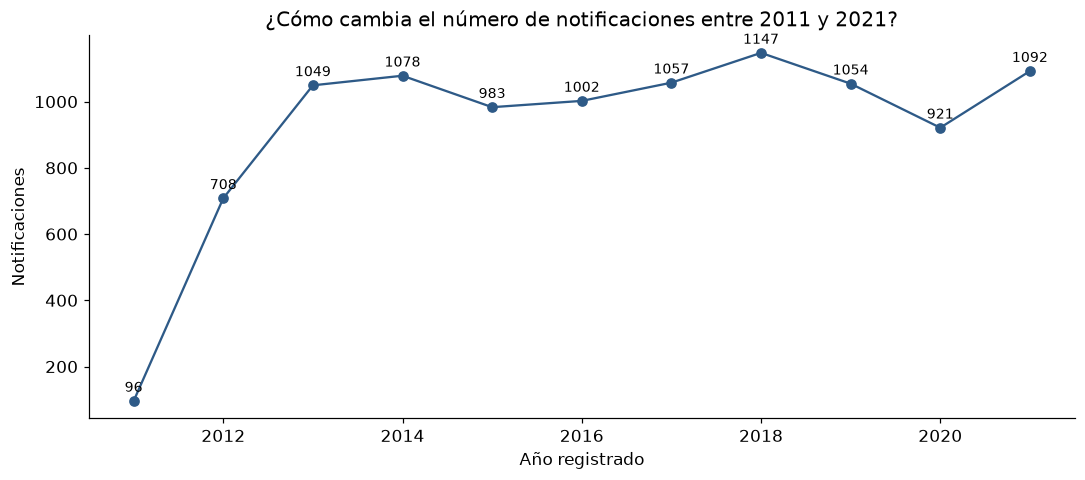

**Lectura:** 2011 tiene 96 registros; el máximo es 1,147 en 2018.

**Límite:** No demuestra cambios en incidencia ni cobertura completa del registro.

In [7]:
lecturas_figuras = []
def guardar_figura(figura, archivo, pregunta, cifra, limite):
    figura.tight_layout()
    figura.savefig(SALIDAS / archivo, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(figura)
    display(Markdown(f"**Lectura:** {cifra}\n\n**Límite:** {limite}"))
    lecturas_figuras.append({"archivo": archivo, "pregunta": pregunta,
                             "lectura": cifra, "limite": limite})

casos_anio = df.groupby("year_").size()
pregunta = "¿Cómo cambia el número de notificaciones entre 2011 y 2021?"
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(casos_anio.index.astype(int), casos_anio.values, marker="o", color="#2e5a87")
for anio, conteo in casos_anio.items():
    ax.annotate(str(conteo), (anio, conteo), xytext=(0, 6),
                textcoords="offset points", ha="center", fontsize=9)
ax.set(title=pregunta, xlabel="Año registrado", ylabel="Notificaciones")
guardar_figura(fig, "01_notificaciones_anio.png", pregunta,
               f"2011 tiene {casos_anio.loc[2011]:,} registros; "
               f"el máximo es {casos_anio.max():,} en {int(casos_anio.idxmax())}.",
               "No demuestra cambios en incidencia ni cobertura completa del registro.")

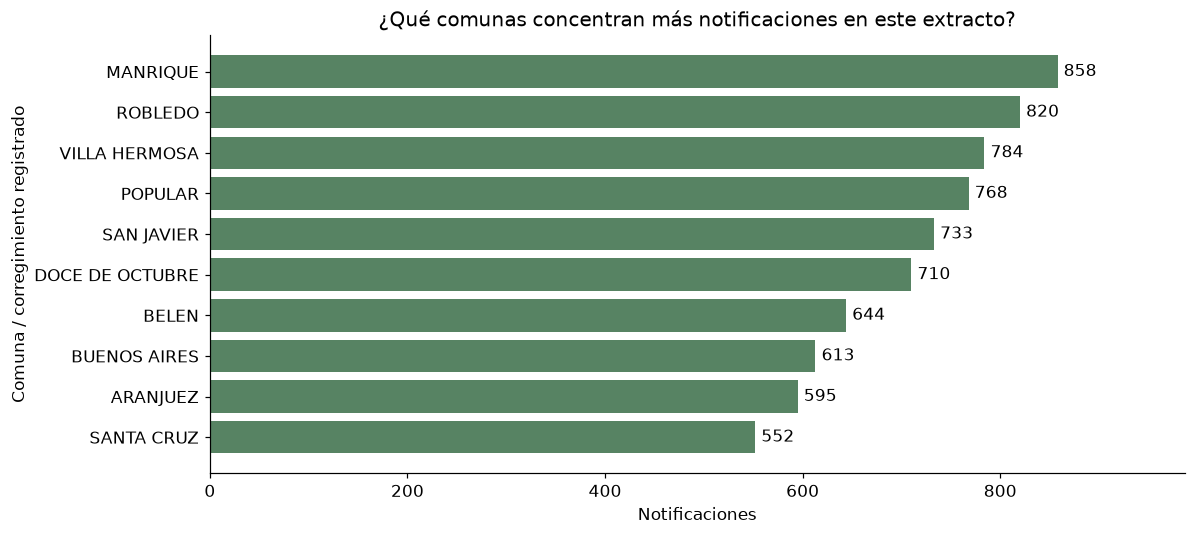

**Lectura:** MANRIQUE reúne 858 registros.

**Límite:** Más casos no significa más riesgo: falta el total de nacimientos por comuna.

In [8]:
casos_comuna = df["comuna"].fillna("SIN DATO").value_counts().head(10).sort_values()
pregunta = "¿Qué comunas concentran más notificaciones en este extracto?"
fig, ax = plt.subplots(figsize=(11, 5))
barras = ax.barh(casos_comuna.index, casos_comuna.values, color="#578363")
ax.bar_label(barras, padding=4)
ax.set_xlim(0, casos_comuna.max()*1.15)
ax.set(title=pregunta, xlabel="Notificaciones", ylabel="Comuna / corregimiento registrado")
guardar_figura(fig, "02_notificaciones_comuna.png", pregunta,
               f"{casos_comuna.idxmax()} reúne {casos_comuna.max():,} registros.",
               "Más casos no significa más riesgo: falta el total de nacimientos por comuna.")

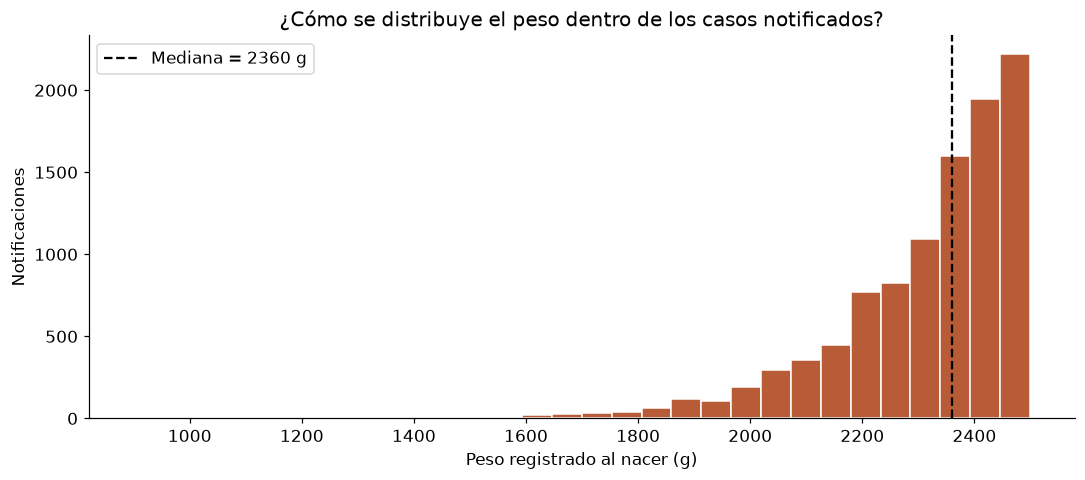

**Lectura:** La mediana es 2360 g; el rango observado es 900–2499 g.

**Límite:** El extracto contiene bajo peso; no representa la distribución de todos los nacimientos.

In [9]:
pesos_validos = df["peso_nacer"].dropna()
pregunta = "¿Cómo se distribuye el peso dentro de los casos notificados?"
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(pesos_validos, bins=30, color="#b85c38", edgecolor="white")
ax.axvline(pesos_validos.median(), color="black", linestyle="--",
           label=f"Mediana = {pesos_validos.median():.0f} g")
ax.set(title=pregunta, xlabel="Peso registrado al nacer (g)", ylabel="Notificaciones")
ax.legend()
guardar_figura(fig, "03_distribucion_peso.png", pregunta,
               f"La mediana es {pesos_validos.median():.0f} g; "
               f"el rango observado es {pesos_validos.min():.0f}–{pesos_validos.max():.0f} g.",
               "El extracto contiene bajo peso; no representa la distribución de todos los nacimientos.")

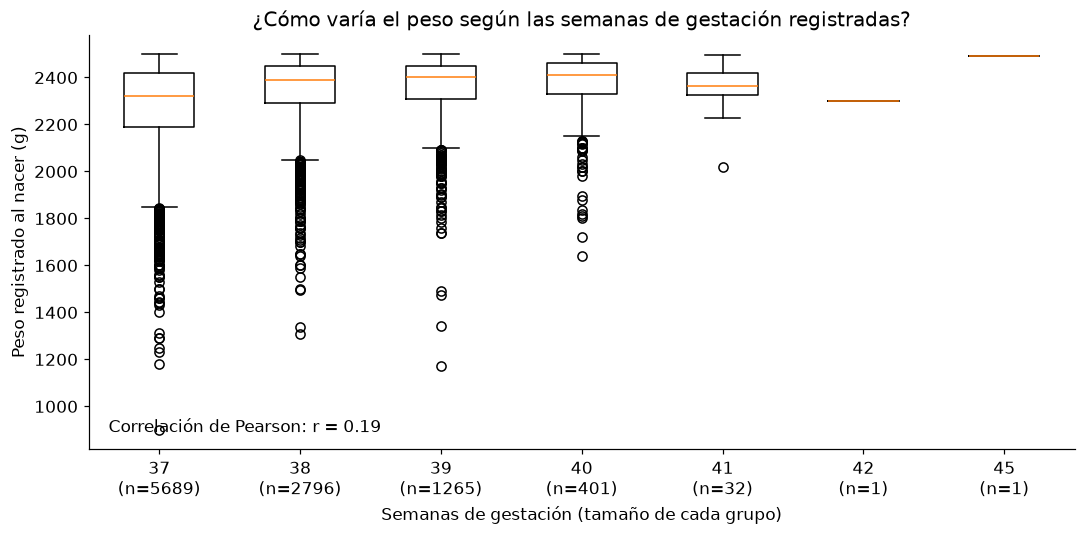

**Lectura:** La correlación en los pares completos es r = 0.19.

**Límite:** Es asociación dentro de una muestra seleccionada. El registro de 45 semanas se conserva señalado; no se infiere causalidad ni se extrapola a prematuros no observados.

In [10]:
correlacion = df[["sem_gest", "peso_nacer"]].corr().iloc[0, 1]
grupos = df.dropna(subset=["sem_gest", "peso_nacer"]).groupby("sem_gest")
pregunta = "¿Cómo varía el peso según las semanas de gestación registradas?"
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([grupo["peso_nacer"].to_numpy() for _, grupo in grupos],
           tick_labels=[f"{semana:.0f}\n(n={len(grupo)})" for semana, grupo in grupos],
           showfliers=True)
ax.set(title=pregunta, xlabel="Semanas de gestación (tamaño de cada grupo)",
       ylabel="Peso registrado al nacer (g)")
ax.text(0.02, 0.04, f"Correlación de Pearson: r = {correlacion:.2f}", transform=ax.transAxes)
guardar_figura(fig, "04_gestacion_peso.png", pregunta,
               f"La correlación en los pares completos es r = {correlacion:.2f}.",
               "Es asociación dentro de una muestra seleccionada. El registro de 45 semanas "
               "se conserva señalado; no se infiere causalidad ni se extrapola a prematuros no observados.")

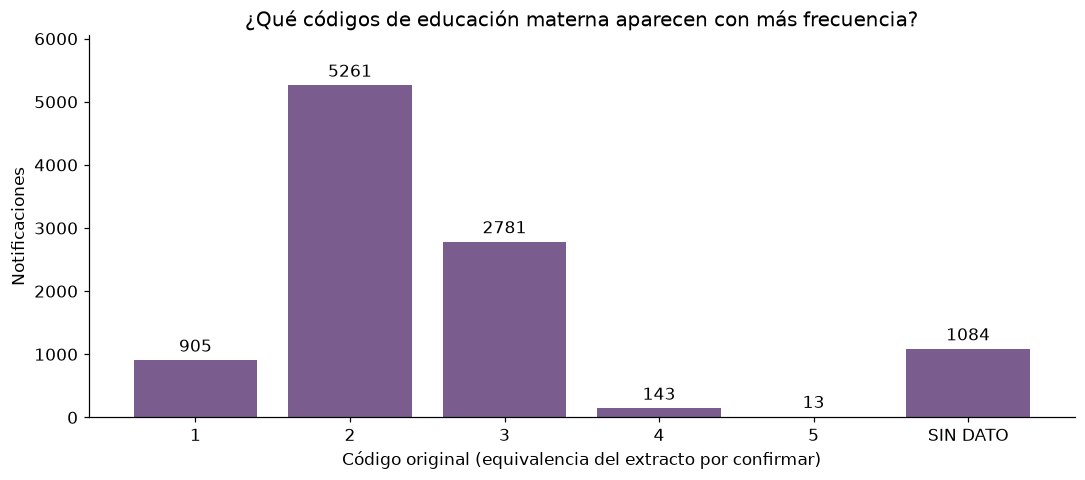

**Lectura:** El código más frecuente es 2, con 5,261 registros.

**Límite:** Sin diccionario específico no se traduce el código 2 como primaria ni se calcula un riesgo por nivel educativo.

In [11]:
educacion_codigos = df["niv_edu_ma"].fillna("SIN DATO").value_counts().sort_index()
pregunta = "¿Qué códigos de educación materna aparecen con más frecuencia?"
fig, ax = plt.subplots(figsize=(10, 4.5))
barras = ax.bar(educacion_codigos.index, educacion_codigos.values, color="#7a5c8e")
ax.bar_label(barras, padding=3)
ax.set_ylim(0, educacion_codigos.max()*1.15)
ax.set(title=pregunta, xlabel="Código original (equivalencia del extracto por confirmar)",
       ylabel="Notificaciones")
guardar_figura(fig, "05_educacion_codigos.png", pregunta,
               f"El código más frecuente es {educacion_codigos.idxmax()}, con "
               f"{educacion_codigos.max():,} registros.",
               "Sin diccionario específico no se traduce el código 2 como primaria "
               "ni se calcula un riesgo por nivel educativo.")

## 5. Contrato predictivo y separación
**y:** estimar `peso_nacer` en gramos dentro de los registros que ya pertenecen al evento bajo peso. Es regresión.

**Momento de referencia:** al parto, antes de leer la báscula, con semanas de gestación y antecedentes administrativos disponibles. La pertenencia al conjunto de bajo peso se conoce retrospectivamente: esta evaluación no acredita un predictor prenatal ni una clasificación de bajo peso.

**X:** `sem_gest`, `comuna`, `tipo_ss_` y `niv_edu_ma`. Las tres últimas se tratan como categorías sin orden. Se asume que estos antecedentes estaban disponibles; el CSV no proporciona marcas temporales para comprobarlo.

Se excluyen talla y hospitalización por disponibilidad/consecuencia potencial, edad y sexo genéricos por semántica ambigua, e identificadores/fechas administrativas.

Se reserva 20% para prueba con semilla 42. No se imputa y ni se pierde una fila por faltantes de X. El split aleatorio evalúa otros registros de esta muestra, no años futuros; sin identificador de madre no puede descartarse dependencia entre registros.

In [12]:
OBJETIVO = "peso_nacer"
NUMERICAS_X = ["sem_gest"]
CATEGORICAS_X = ["comuna", "tipo_ss_", "niv_edu_ma"]
COLUMNAS_X = NUMERICAS_X + CATEGORICAS_X
datos_modelo = df.loc[df[OBJETIVO].notna(), COLUMNAS_X + [OBJETIVO]].copy()
X = datos_modelo[COLUMNAS_X].astype(object).where(datos_modelo[COLUMNAS_X].notna(), np.nan)
X["sem_gest"] = pd.to_numeric(X["sem_gest"], errors="coerce")
y = datos_modelo[OBJETIVO].astype(float)
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA)
assert set(X_entrenamiento.index).isdisjoint(X_prueba.index)
print(f"Filas originales: {len(df):,}")
print(f"Excluidas solo por y ausente/fuera de alcance: {len(df)-len(datos_modelo):,}")
print(f"Entrenamiento: {len(X_entrenamiento):,}; prueba: {len(X_prueba):,}")
display(X_entrenamiento.isna().sum().to_frame("faltantes_X_entrenamiento"))

Filas originales: 10,187
Excluidas solo por y ausente/fuera de alcance: 2
Entrenamiento: 8,148; prueba: 2,037


,faltantes_X_entrenamiento
sem_gest,0
comuna,345
tipo_ss_,0
niv_edu_ma,866


### 5.1 Baseline antes del árbol
Se mide primero un `DummyRegressor` que siempre predice la **media del entrenamiento**. Se añade la **mediana del entrenamiento**, referencia apropiada para MAE y distribuciones asimétricas.

**MAE:** promedio del error absoluto; se expresa en gramos. Un MAE menor es mejor. R² es complementario y puede ser negativo. Ambos baselines se comparan en exactamente las mismas filas de prueba; no eligen hiperparámetros.

In [13]:
filas_metricas = []
def evaluar(nombre, reales, predicciones):
    return {"modelo": nombre, "MAE_g": float(mean_absolute_error(reales, predicciones)),
            "R2": float(r2_score(reales, predicciones))}

for estrategia in ["mean", "median"]:
    referencia = DummyRegressor(strategy=estrategia).fit(X_entrenamiento, y_entrenamiento)
    prediccion = referencia.predict(X_prueba)
    etiqueta = "Baseline media" if estrategia == "mean" else "Baseline mediana"
    filas_metricas.append(evaluar(etiqueta, y_prueba, prediccion))
    print(f"{etiqueta}: predice siempre {referencia.constant_.item():.2f} g")
display(pd.DataFrame(filas_metricas).set_index("modelo").round(4))

Baseline media: predice siempre 2311.26 g
Baseline mediana: predice siempre 2360.00 g


,MAE_g,R2
modelo,,
Baseline media,122.9018,-0.0068
Baseline mediana,115.2293,-0.0538


## 6. Árbol de decisión con preparación dentro del entrenamiento
La mediana numérica se aprende del entrenamiento; las categorías ausentes se representan como `SIN DATO`. One-hot crea una columna por código/categoría y evita fingir un orden entre comunas o niveles. `handle_unknown="ignore"` permite categorías nuevas en prueba.

La profundidad se elige con validación cruzada de cinco particiones **solo en entrenamiento**. Se fija un mínimo de 20 registros por hoja para limitar divisiones muy pequeñas. La prueba no selecciona profundidad ni umbrales. No se garantiza que el árbol supere al baseline.

In [14]:
preparacion = ColumnTransformer([
    ("numericas", SimpleImputer(strategy="median"), NUMERICAS_X),
    ("categoricas", Pipeline([
        ("faltantes", SimpleImputer(strategy="constant", fill_value="SIN DATO")),
        ("codigos", OneHotEncoder(handle_unknown="ignore"))
    ]), CATEGORICAS_X)
])
pipeline = Pipeline([
    ("preparacion", preparacion),
    ("arbol", DecisionTreeRegressor(random_state=SEMILLA, min_samples_leaf=20))
])
validacion = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
busqueda = GridSearchCV(
    pipeline, {"arbol__max_depth": [1, 2, 3, 4, 5, 6, 8, 10]},
    scoring="neg_mean_absolute_error", cv=validacion, n_jobs=1, error_score="raise")
busqueda.fit(X_entrenamiento, y_entrenamiento)
modelo = busqueda.best_estimator_
resultados_cv = pd.DataFrame({
    "profundidad": [p["arbol__max_depth"] for p in busqueda.cv_results_["params"]],
    "MAE_validacion_g": -busqueda.cv_results_["mean_test_score"],
    "desviacion_entre_particiones_g": busqueda.cv_results_["std_test_score"]
})
print("Profundidad elegida:", busqueda.best_params_["arbol__max_depth"])
display(resultados_cv.round(3))
resultados_cv.to_csv(SALIDAS / "validacion_cruzada.csv", index=False)

Profundidad elegida: 2


,profundidad,MAE_validacion_g,desviacion_entre_particiones_g
0,1,124.486,3.221
1,2,124.436,3.347
2,3,124.455,3.397
3,4,124.659,3.430
4,5,124.822,3.481
5,6,125.114,3.627
6,8,125.228,3.738
7,10,125.462,3.520


### 6.1 Qué le pasó a la distribución al imputar
No se imputa talla, edad ni peso. Solo se contempla mediana para semanas de gestación en X, aprendida del entrenamiento. La tabla muestra cuántos valores se rellenaron y si cambiaron la media y la desviación estándar. Si no hay faltantes en esta partición, el método no altera la distribución. Imputar con un solo valor puede reducir la dispersión; no se presenta como una observación medida.

In [15]:
semanas_antes = X_entrenamiento["sem_gest"].astype(float)
imputador = modelo.named_steps["preparacion"].named_transformers_["numericas"]
semanas_despues = pd.Series(imputador.transform(X_entrenamiento[NUMERICAS_X]).ravel())
efecto_imputacion = pd.DataFrame({
    "antes_observados": semanas_antes.describe(),
    "despues_incluidos_imputados": semanas_despues.describe()
})
print("Mediana aprendida:", imputador.statistics_[0])
print("Imputados en entrenamiento:", int(semanas_antes.isna().sum()))
print("Faltantes de semanas en prueba:", int(X_prueba.sem_gest.isna().sum()))
display(efecto_imputacion.round(5))
efecto_imputacion.to_csv(SALIDAS / "efecto_imputacion.csv", index=True)

Mediana aprendida: 37.0
Imputados en entrenamiento: 0
Faltantes de semanas en prueba: 0


,antes_observados,despues_incluidos_imputados
count,8148.00000,8148.00000
mean,37.65010,37.65010
std,0.87106,0.87106
min,37.00000,37.00000
25%,37.00000,37.00000
50%,37.00000,37.00000
75%,38.00000,38.00000
max,45.00000,45.00000


## 7. Resultado final frente a las dos referencias
Se hace una sola evaluación final del árbol elegido sobre prueba. El error de entrenamiento se muestra para detectar memorización; no sustituye la métrica de prueba. La comparación describe este split y no demuestra por sí sola una mejora estadísticamente estable.

,MAE_g,R2
modelo,,
Baseline media,122.9018,-0.0068
Baseline mediana,115.2293,-0.0538
Árbol,118.1692,0.0424


MAE entrenamiento árbol: 124.32 g
Mejora vs. media: +3.85%; vs. mediana: -2.55%


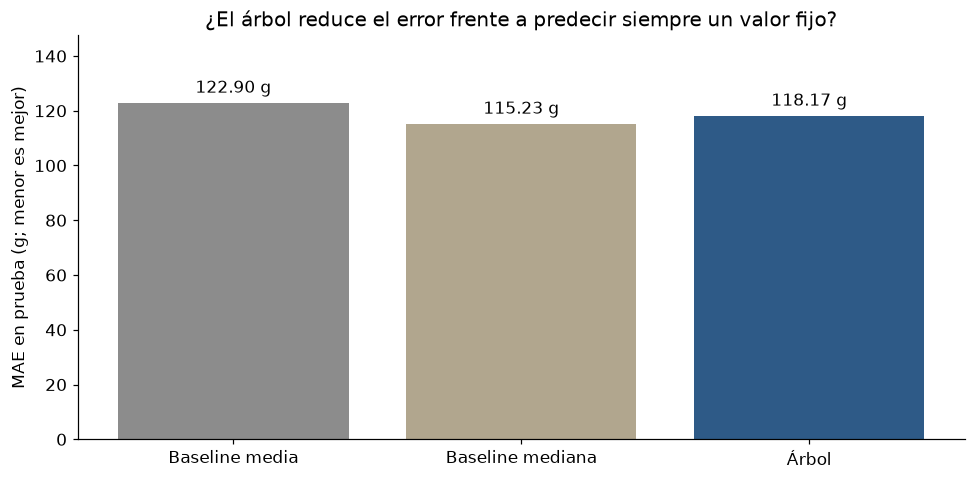

**Lectura:** Árbol: 118.17 g; media: 122.90 g; mediana: 115.23 g.

**Límite:** Una diferencia en un split no prueba significación ni rendimiento futuro.

In [16]:
predicciones_prueba = modelo.predict(X_prueba)
predicciones_entrenamiento = modelo.predict(X_entrenamiento)
filas_metricas.append(evaluar("Árbol", y_prueba, predicciones_prueba))
metricas = pd.DataFrame(filas_metricas).set_index("modelo")
mae_arbol = metricas.loc["Árbol", "MAE_g"]
mejora_media = (1-mae_arbol/metricas.loc["Baseline media", "MAE_g"])*100
mejora_mediana = (1-mae_arbol/metricas.loc["Baseline mediana", "MAE_g"])*100
mae_entrenamiento = mean_absolute_error(y_entrenamiento, predicciones_entrenamiento)
display(metricas.round(4))
print(f"MAE entrenamiento árbol: {mae_entrenamiento:.2f} g")
print(f"Mejora vs. media: {mejora_media:+.2f}%; vs. mediana: {mejora_mediana:+.2f}%")
metricas.to_csv(SALIDAS / "metricas_prueba.csv", index=True)

pregunta = "¿El árbol reduce el error frente a predecir siempre un valor fijo?"
fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.bar(metricas.index, metricas["MAE_g"], color=["#8c8c8c", "#b1a68e", "#2e5a87"])
ax.bar_label(barras, labels=[f"{v:.2f} g" for v in metricas.MAE_g], padding=4)
ax.set_ylim(0, metricas.MAE_g.max()*1.2)
ax.set(title=pregunta, ylabel="MAE en prueba (g; menor es mejor)")
guardar_figura(fig, "06_comparacion_modelos.png", pregunta,
               f"Árbol: {mae_arbol:.2f} g; media: {metricas.loc['Baseline media','MAE_g']:.2f} g; "
               f"mediana: {metricas.loc['Baseline mediana','MAE_g']:.2f} g.",
               "Una diferencia en un split no prueba significación ni rendimiento futuro.")

### 7.1 Interpretación del mismo árbol evaluado
Se agregan las importancias one-hot por variable original para no confundir una categoría con toda la variable. Son reducciones de impureza del árbol: **no son porcentajes de causalidad ni pruebas de riesgo**.

La visualización limita lo mostrado a los tres primeros niveles, pero corresponde al mismo estimador evaluado; no entrena un segundo modelo con el que puedan confundirse las métricas.

,importancia_pct
variable,
sem_gest,89.79
niv_edu_ma,10.21
comuna,0.00
tipo_ss_,0.00


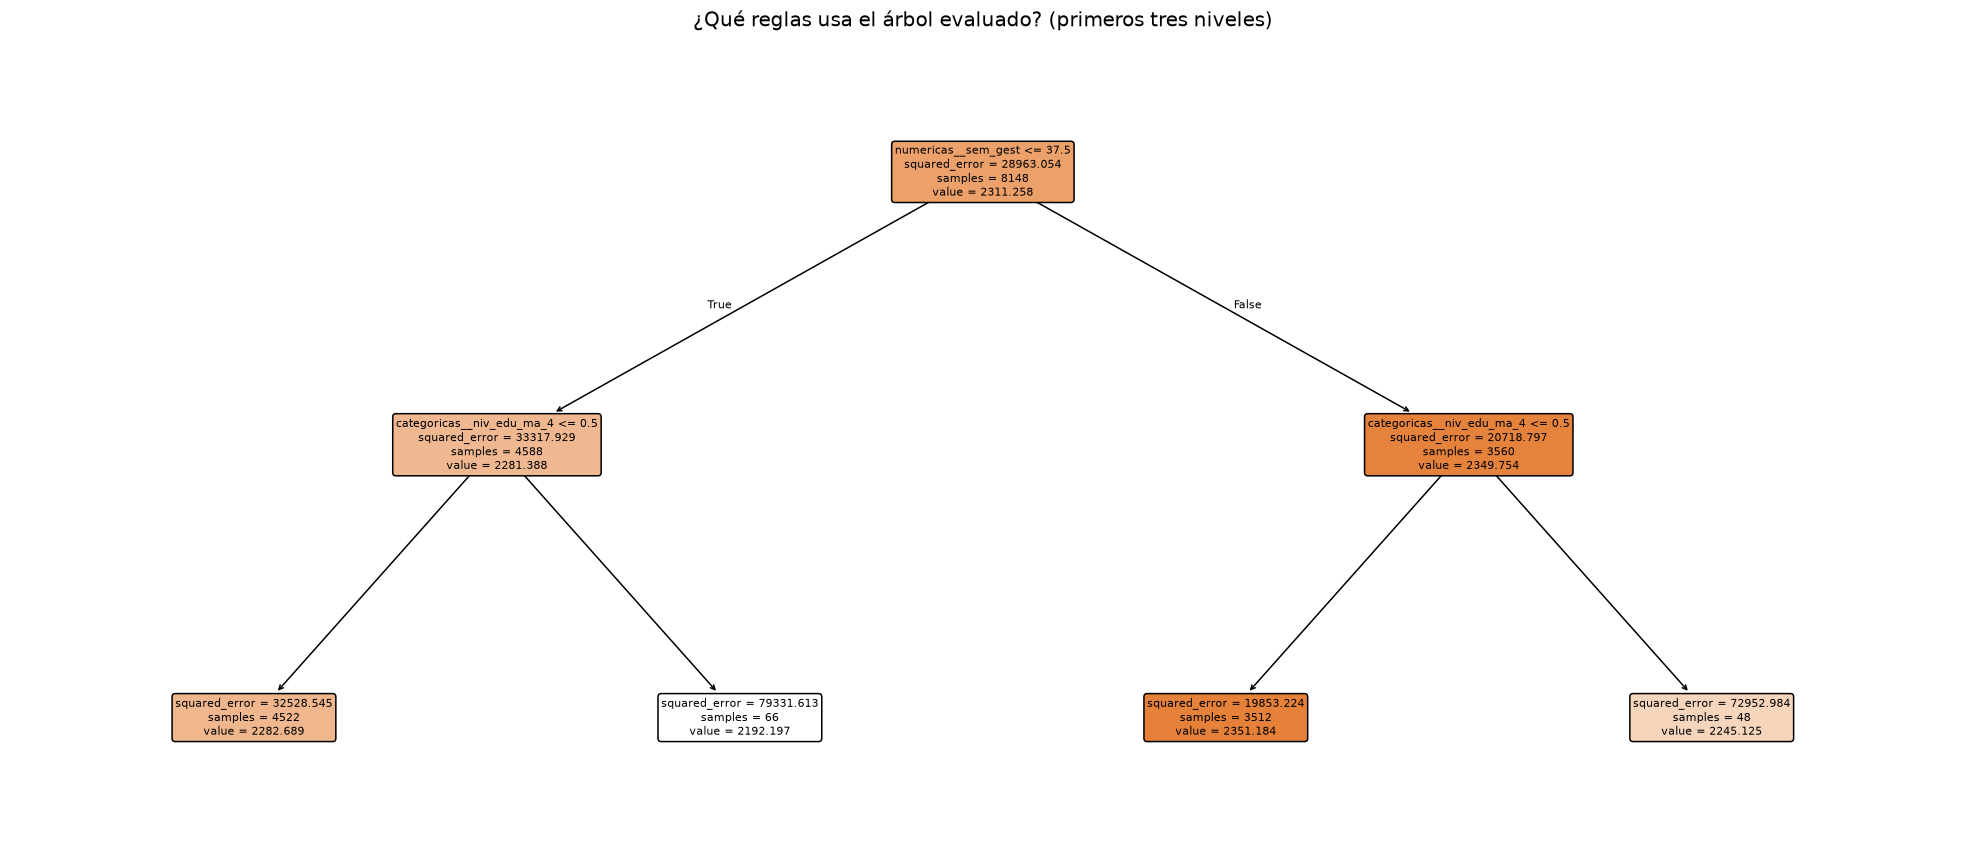

In [17]:
transformador = modelo.named_steps["preparacion"]
codificador = transformador.named_transformers_["categoricas"].named_steps["codigos"]
variables_origen = NUMERICAS_X.copy()
for columna, categorias in zip(CATEGORICAS_X, codificador.categories_):
    variables_origen.extend([columna] * len(categorias))
importancias = pd.DataFrame({
    "variable": variables_origen,
    "importancia": modelo.named_steps["arbol"].feature_importances_
}).groupby("variable").importancia.sum().sort_values(ascending=False)
display(importancias.mul(100).round(2).to_frame("importancia_pct"))
importancias.to_csv(SALIDAS / "importancias_variables.csv", index=True)
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(modelo.named_steps["arbol"], max_depth=3,
          feature_names=transformador.get_feature_names_out(),
          filled=True, rounded=True, fontsize=7, ax=ax)
ax.set_title("¿Qué reglas usa el árbol evaluado? (primeros tres niveles)")
fig.tight_layout()
fig.savefig(SALIDAS / "07_arbol_evaluado.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## 8. Conclusiones y límites
Las conclusiones se basan en las métricas del conjunto de prueba y en la comparación del árbol con los baselines de media y mediana.

La escasa variación del peso puede limitar la señal disponible, pero no demuestra por sí sola por qué el modelo rinde así. Tampoco una variable con importancia cero prueba que carezca de relación con el fenómeno.

In [18]:
dominante = importancias.idxmax()
comparacion_media = "reduce" if mejora_media > 0 else "no reduce"
comparacion_mediana = "reduce" if mejora_mediana > 0 else "no reduce"
texto_conclusion = f"""
El árbol de profundidad **{busqueda.best_params_['arbol__max_depth']}** obtiene
**MAE = {mae_arbol:.2f} g** y **R² = {metricas.loc['Árbol','R2']:.4f}** en prueba.
La referencia de media obtiene **{metricas.loc['Baseline media','MAE_g']:.2f} g**
y la de mediana **{metricas.loc['Baseline mediana','MAE_g']:.2f} g**.
El árbol **{comparacion_media}** el MAE frente a la media
(cambio relativo {mejora_media:+.2f}%) y **{comparacion_mediana}**
el MAE frente a la mediana ({mejora_mediana:+.2f}%).
No se afirma superioridad general a partir de esta única partición.

La variable con mayor importancia es **{dominante}**
(**{importancias.iloc[0]*100:.2f}%** de la reducción de impureza).
Esto describe reglas predictivas, no efectos causales.
El peso observado va de **{pesos_validos.min():.0f} a {pesos_validos.max():.0f} g**,
con desviación estándar **{pesos_validos.std():.2f} g**; las semanas van de
**{df.sem_gest.min():.0f} a {df.sem_gest.max():.0f}**.
La selección de casos y el rango observado restringen la extrapolación.
La relación gestación–peso es **r = {correlacion:.2f}** en pares completos.

**Qué no concluyo:** no estimo el riesgo por comuna o educación, no predigo
todos los nacimientos, no identifico causas y no demuestro rendimiento en años
futuros. Faltan denominadores, diccionario específico del extracto, disponibilidad
temporal de los predictores y validación externa. Los extremos señalados necesitan
revisión de la fuente, no una eliminación automática.
"""
display(Markdown(texto_conclusion))
resumen = {
    "autor": "Jesid Alexander López Álvarez",
    "fuente_csv": URL_DATOS, "sha256": sha256,
    "filas_crudas": len(datos_crudos), "columnas_crudas": datos_crudos.shape[1],
    "fallos_conversion": int(auditoria_parseo.fallos_conversion.sum()),
    "duplicados_exactos": duplicados_exactos,
    "filas_modelo": len(datos_modelo),
    "entrenamiento": len(X_entrenamiento), "prueba": len(X_prueba),
    "X": COLUMNAS_X, "y": OBJETIVO, "semilla": SEMILLA,
    "profundidad": busqueda.best_params_["arbol__max_depth"],
    "min_samples_leaf": 20, "MAE_entrenamiento": float(mae_entrenamiento),
    "metricas_prueba": metricas.reset_index().to_dict(orient="records"),
    "mejora_vs_media_pct": float(mejora_media),
    "mejora_vs_mediana_pct": float(mejora_mediana),
    "correlacion_gestacion_peso": float(correlacion),
    "importancias_pct": importancias.mul(100).to_dict(),
    "figuras": lecturas_figuras
}
(SALIDAS / "resumen_resultados.json").write_text(
    json.dumps(resumen, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
(SALIDAS / "conclusion.txt").write_text(texto_conclusion, encoding="utf-8")
print("Evidencias guardadas en:", SALIDAS.resolve())


El árbol de profundidad **2** obtiene
**MAE = 118.17 g** y **R² = 0.0424** en prueba.
La referencia de media obtiene **122.90 g**
y la de mediana **115.23 g**.
El árbol **reduce** el MAE frente a la media
(cambio relativo +3.85%) y **no reduce**
el MAE frente a la mediana (-2.55%).
No se afirma superioridad general a partir de esta única partición.

La variable con mayor importancia es **sem_gest**
(**89.79%** de la reducción de impureza).
Esto describe reglas predictivas, no efectos causales.
El peso observado va de **900 a 2499 g**,
con desviación estándar **167.32 g**; las semanas van de
**37 a 45**.
La selección de casos y el rango observado restringen la extrapolación.
La relación gestación–peso es **r = 0.19** en pares completos.

**Qué no concluyo:** no estimo el riesgo por comuna o educación, no predigo
todos los nacimientos, no identifico causas y no demuestro rendimiento en años
futuros. Faltan denominadores, diccionario específico del extracto, disponibilidad
temporal de los predictores y validación externa. Los extremos señalados necesitan
revisión de la fuente, no una eliminación automática.


Evidencias guardadas en: E:\programacion\proyectos\Introduccion-a-la-programacion-cientifica\notebooks\salidas_tarea2
